In [46]:
conda install seaborn -c conda-forge

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.953 seconds
All requested packages already installed.


In [47]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
%matplotlib inline

In [48]:
import warnings
warnings.filterwarnings('ignore')

In [49]:
df1 = pd.read_csv('student-mat.csv', sep = ';')
df2 = pd.read_csv('student-por.csv', sep = ';')

In [50]:
print(df1.shape)
print(df2.shape)

(395, 33)
(649, 33)


In [51]:
df1.columns == df2.columns


array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True])

In [52]:
df_common = pd.merge(df1, df2, how = 'inner', on = ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'])


In [53]:
df_common.shape


(0, 33)

In [54]:
df = pd.concat([df1, df2], ignore_index = True) # pd.concat([df1, df2], axis = 0)
df.shape

(1044, 33)

In [55]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [56]:
df.tail(649)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
395,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
396,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
397,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
398,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
399,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1039,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
1040,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
1041,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
1042,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [57]:
df.index.duplicated().sum()


np.int32(0)

In [58]:
df.columns == df1.columns


array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True])

In [59]:
df.columns


Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

In [60]:
df.columns = ['school', 'sex', 'age', 'address', 'fam_size', 'parents_status', 'mother_edu', 'father_edu',
       'mother_job', 'father_job', 'reason', 'guardian', 'travel_time', 'study_time',
       'failures', 'school_support', 'fam_support', 'paid_courses', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'fam_rel', 'free_time', 'go_out', 'weekday_alc',
       'weekend_alc', 'health', 'absences', 'G1', 'G2', 'final_grade']

In [61]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   school          1044 non-null   str  
 1   sex             1044 non-null   str  
 2   age             1044 non-null   int64
 3   address         1044 non-null   str  
 4   fam_size        1044 non-null   str  
 5   parents_status  1044 non-null   str  
 6   mother_edu      1044 non-null   int64
 7   father_edu      1044 non-null   int64
 8   mother_job      1044 non-null   str  
 9   father_job      1044 non-null   str  
 10  reason          1044 non-null   str  
 11  guardian        1044 non-null   str  
 12  travel_time     1044 non-null   int64
 13  study_time      1044 non-null   int64
 14  failures        1044 non-null   int64
 15  school_support  1044 non-null   str  
 16  fam_support     1044 non-null   str  
 17  paid_courses    1044 non-null   str  
 18  activities      1044 non-null   str  
 

In [62]:
df.head()


,school,sex,age,address,fam_size,parents_status,mother_edu,father_edu,mother_job,father_job,...,fam_rel,free_time,go_out,weekday_alc,weekend_alc,health,absences,G1,G2,final_grade
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [63]:
df = df.drop_duplicates(subset = None, keep = 'first', inplace = False)
df.shape    #no duplicates in train_por

(1044, 33)

In [64]:
df.columns[df.isna().any()]


Index([], dtype='str')

In [65]:
df.describe()


,age,mother_edu,father_edu,travel_time,study_time,failures,fam_rel,free_time,go_out,weekday_alc,weekend_alc,health,absences,G1,G2,final_grade
count,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,16.726054,2.603448,2.387931,1.522989,1.970307,0.264368,3.935824,3.201149,3.156130,1.494253,2.284483,3.543103,4.434866,11.213602,11.246169,11.341954
std,1.239975,1.124907,1.099938,0.731727,0.834353,0.656142,0.933401,1.031507,1.152575,0.911714,1.285105,1.424703,6.210017,2.983394,3.285071,3.864796
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,9.000000,9.000000,10.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [66]:
sorted(df.final_grade.unique())


[np.int64(0),
 np.int64(1),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17),
 np.int64(18),
 np.int64(19),
 np.int64(20)]

In [67]:
np.where(df.columns == 'final_grade')


(array([32]),)

In [68]:
df['remarks'] = 'na'
df.iloc[0, 33] ='6'
df.head()

,school,sex,age,address,fam_size,parents_status,mother_edu,father_edu,mother_job,father_job,...,free_time,go_out,weekday_alc,weekend_alc,health,absences,G1,G2,final_grade,remarks
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,na
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,na
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,na
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,na


In [69]:
for i in range(len(df.final_grade)):
    
    grade = df.iloc[i, 32]
    
    if grade <= 11:
        df.iloc[i, 33] = 'Poor'
        
    elif grade > 11 and grade <= 15:
        df.iloc[i, 33] = 'Fair'
        
    else:
        df.iloc[i, 33] = 'Excellent'
df.head()

,school,sex,age,address,fam_size,parents_status,mother_edu,father_edu,mother_job,father_job,...,free_time,go_out,weekday_alc,weekend_alc,health,absences,G1,G2,final_grade,remarks
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,Poor
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,Poor
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,Poor
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,Fair
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,Poor


<Axes: ylabel='final_grade'>

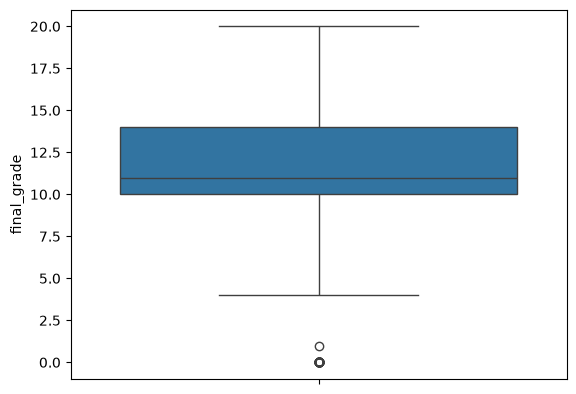

In [70]:
sns.boxplot(df.final_grade)


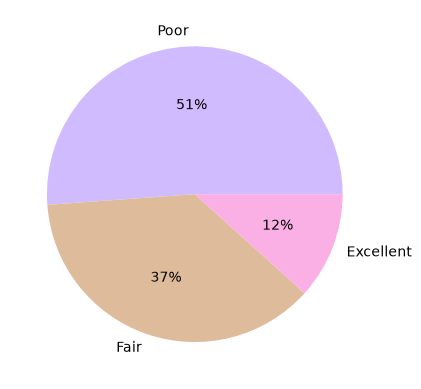

In [71]:
labels = df.remarks.unique()
data = []
for remark in labels:
    data.append(len(df.loc[df.remarks == remark, :]))

palette = sns.color_palette('pastel')[4:7]
plt.pie(data, labels = labels, colors = palette, autopct='%.0f%%')

<Axes: xlabel='remarks', ylabel='age'>

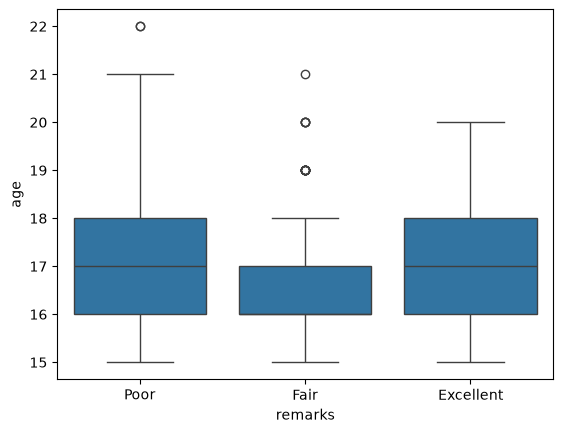

In [72]:
sns.boxplot(data=df, x="remarks", y="age")

In [73]:
df.columns


Index(['school', 'sex', 'age', 'address', 'fam_size', 'parents_status',
       'mother_edu', 'father_edu', 'mother_job', 'father_job', 'reason',
       'guardian', 'travel_time', 'study_time', 'failures', 'school_support',
       'fam_support', 'paid_courses', 'activities', 'nursery', 'higher',
       'internet', 'romantic', 'fam_rel', 'free_time', 'go_out', 'weekday_alc',
       'weekend_alc', 'health', 'absences', 'G1', 'G2', 'final_grade',
       'remarks'],
      dtype='str')

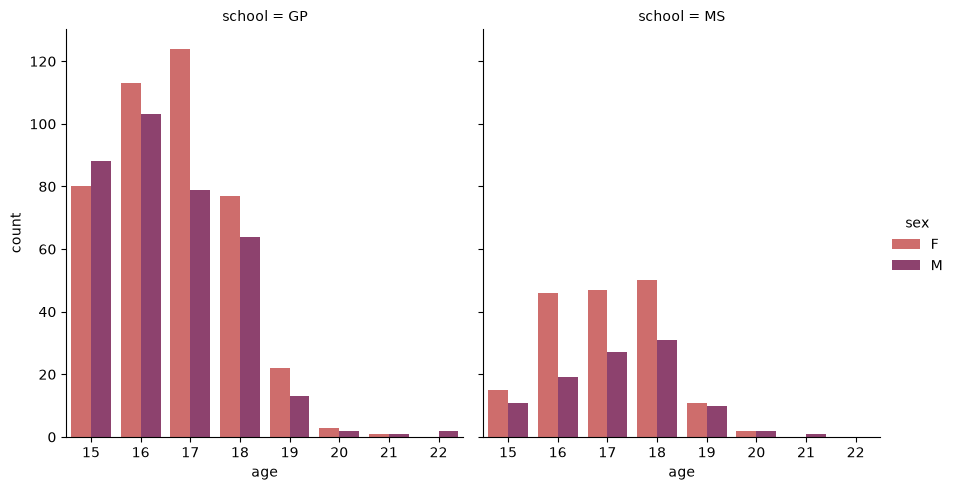

In [74]:
sns.catplot(x = 'age', hue = 'sex', col = 'school', data = df, kind = 'count', palette = 'flare', aspect = 0.9)


In [75]:
perc = (lambda col: col/col.sum())
index = ['Poor','Fair','Excellent']

Text(0.5, 0, 'Final Grade')

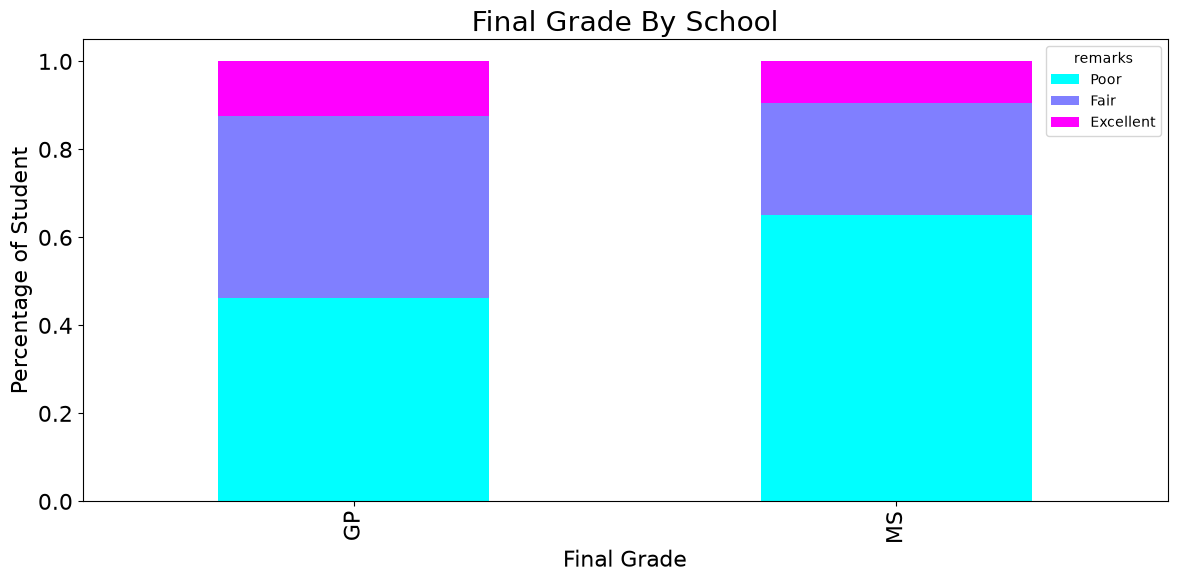

In [76]:
out_tab = pd.crosstab(df.remarks, df.school)
out_perc = out_tab.apply(perc).reindex(index)
out_perc = out_perc.T
out_perc.plot.bar(colormap="cool", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade By School', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

Text(0.5, 0, 'Final Grade')

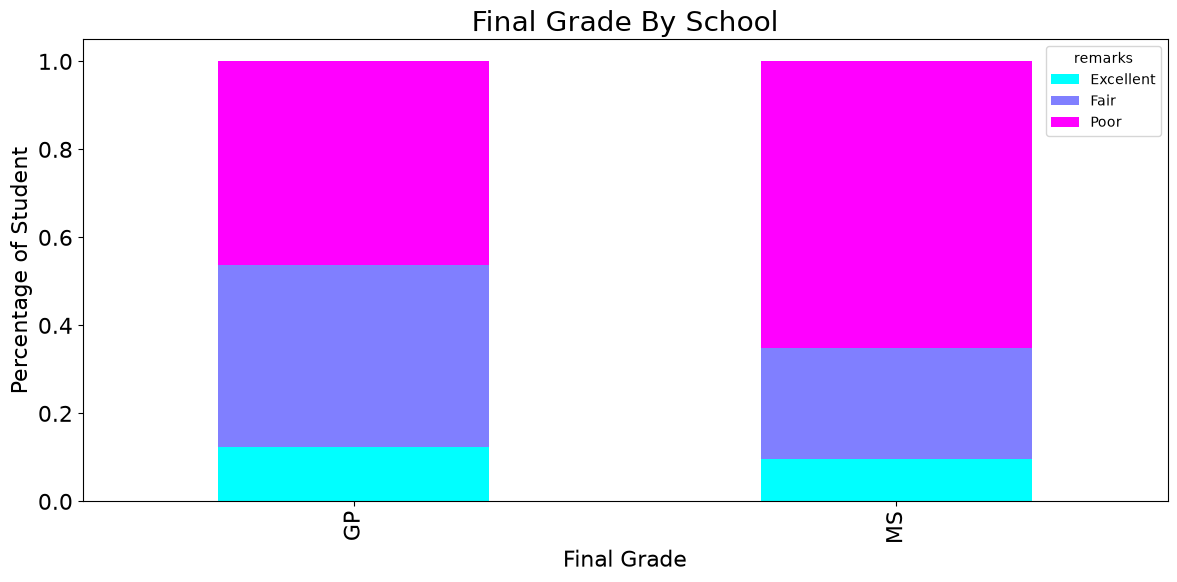

In [77]:
out_tab = pd.crosstab(df.school, df.remarks)
out_perc = out_tab.apply(perc, axis = 1)
out_perc.plot.bar(colormap="cool", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade By School', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

Text(0.5, 0, 'Final Grade')

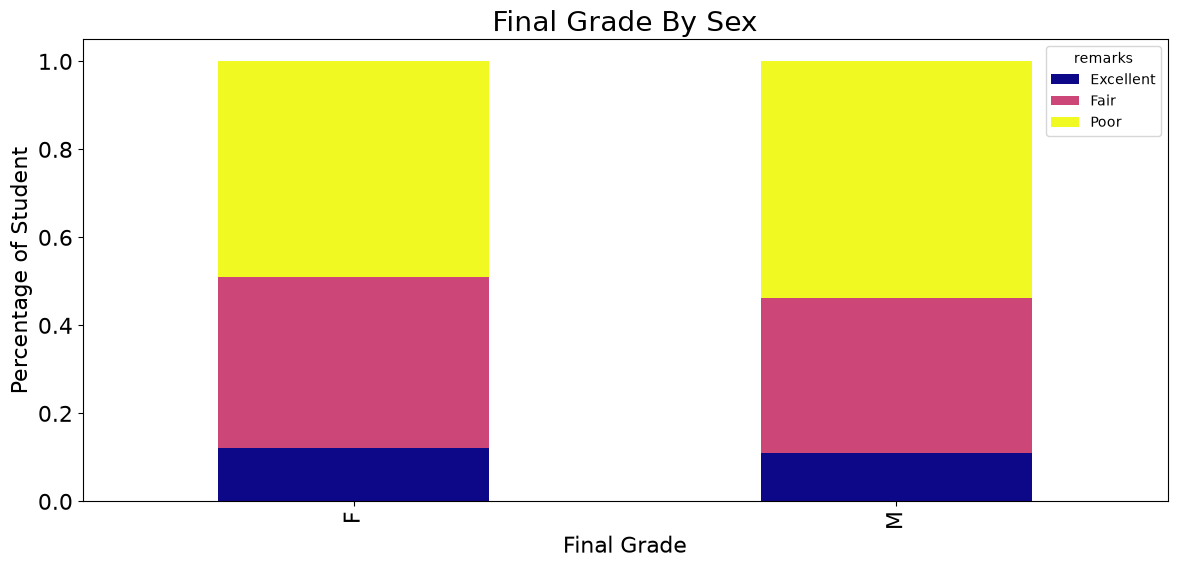

In [78]:
out_tab = pd.crosstab(df.remarks, df.sex)
out_perc = out_tab.apply(perc)
out_perc = out_perc.T
out_perc.plot.bar(colormap = "plasma", fontsize = 16, figsize = (14,6), stacked = True)
plt.title('Final Grade By Sex', fontsize = 20)
plt.ylabel('Percentage of Student', fontsize = 16)
plt.xlabel('Final Grade', fontsize = 16)

<Axes: xlabel='sex', ylabel='final_grade'>

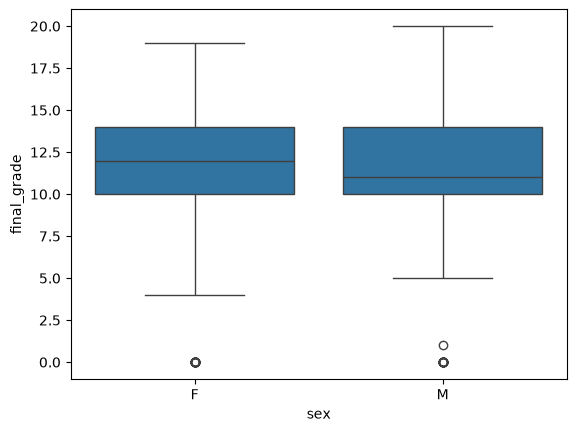

In [79]:
sns.boxplot(data=df,x="sex",y="final_grade")

Text(0.5, 0, 'Final Grade')

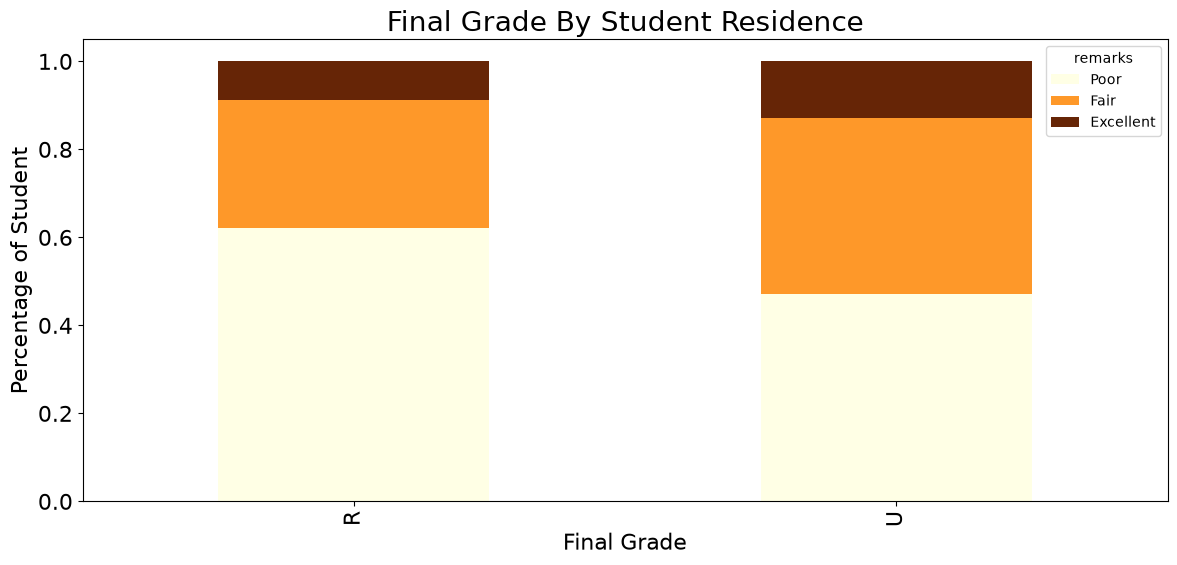

In [80]:
out_tab = pd.crosstab(df.remarks, df.address)
out_perc = out_tab.apply(perc).reindex(index)
out_perc = out_perc.T
out_perc.plot.bar(colormap="YlOrBr", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade By Student Residence', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

Text(0.5, 0, 'Final Grade')

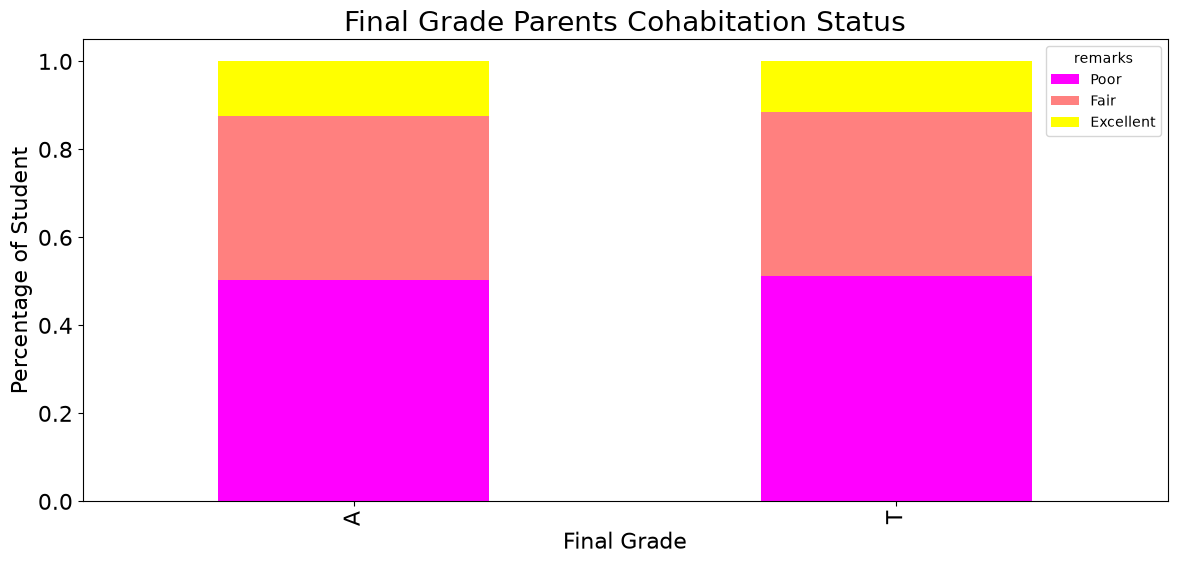

In [81]:
out_tab = pd.crosstab(df.remarks, df.parents_status)
out_perc = out_tab.apply(perc).reindex(index)
out_perc = out_perc.T
out_perc.plot.bar(colormap="spring", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade Parents Cohabitation Status', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

Text(0.5, 0, 'Final Grade')

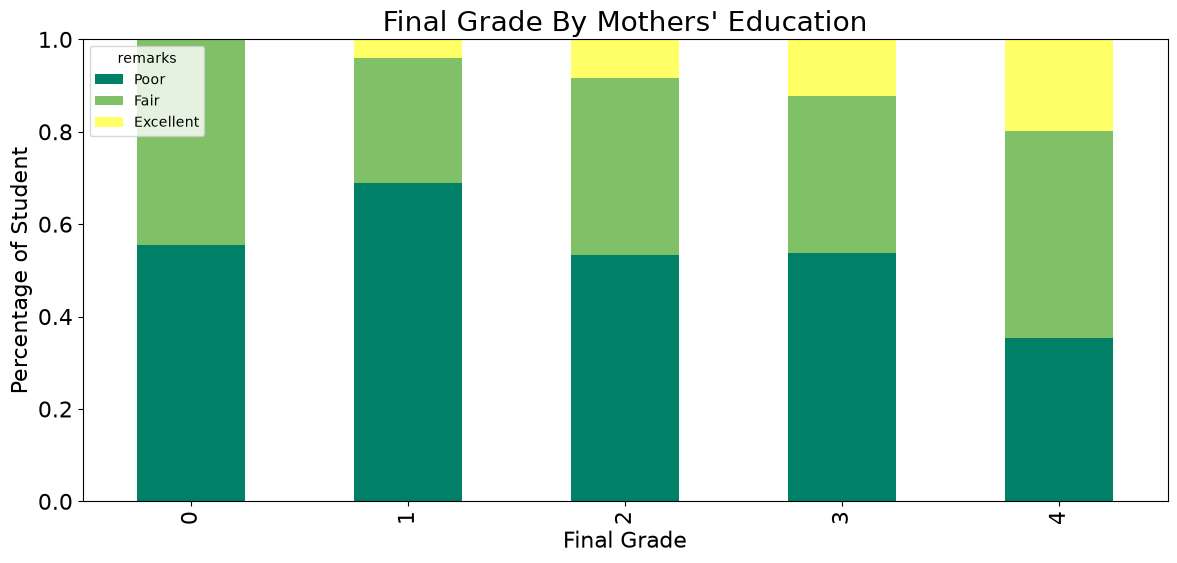

In [82]:
out_tab = pd.crosstab(df.remarks, df.mother_edu)
out_perc = out_tab.apply(perc).reindex(index)
out_perc = out_perc.T
out_perc.plot.bar(colormap="summer", fontsize=16, figsize=(14,6), stacked = True)
plt.title("Final Grade By Mothers' Education", fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

Text(0.5, 0, 'Final Grade')

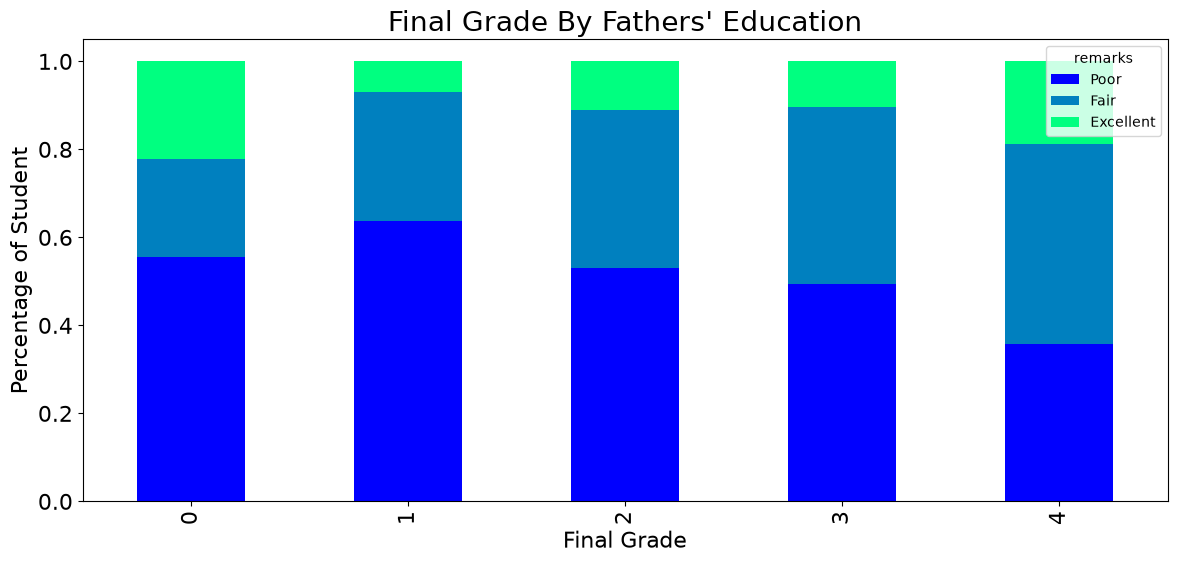

In [83]:
out_tab = pd.crosstab(df.remarks, df.father_edu)
out_perc = out_tab.apply(perc).reindex(index)
out_perc = out_perc.T
out_perc.plot.bar(colormap="winter", fontsize=16, figsize=(14,6), stacked = True)
plt.title("Final Grade By Fathers' Education", fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

Text(0.5, 0, 'Final Grade')

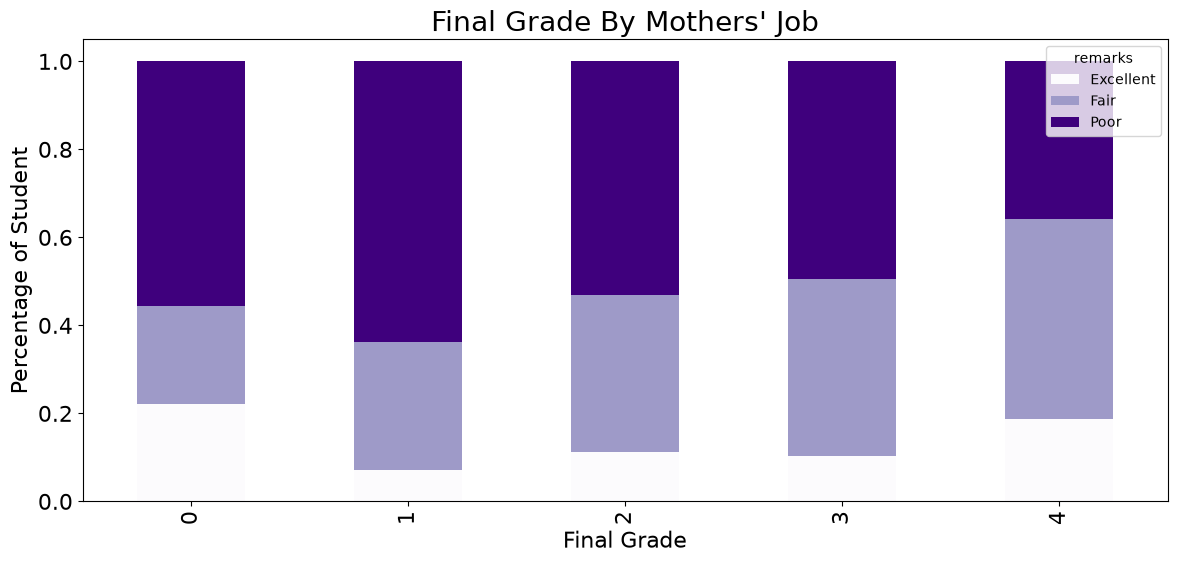

In [84]:
ut_tab = pd.crosstab(df.mother_job, df.remarks)
out_perc = out_tab.apply(perc)
out_perc = out_perc.T
out_perc.plot.bar(colormap="Purples", fontsize=16, figsize=(14,6), stacked = True)
plt.title("Final Grade By Mothers' Job", fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

<Axes: xlabel='mother_job', ylabel='final_grade'>

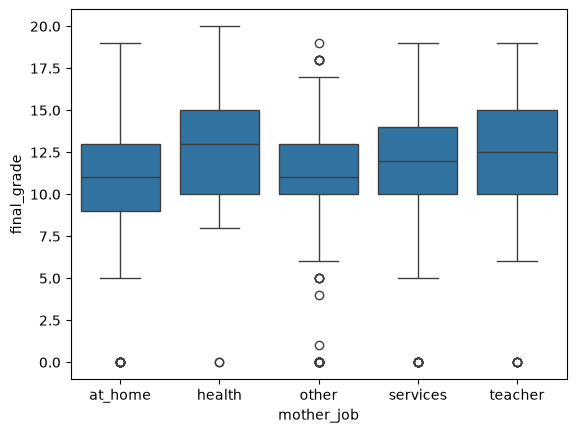

In [85]:
sns.boxplot(data=df,x="mother_job",y="final_grade")

Text(0.5, 0, 'Final Grade')

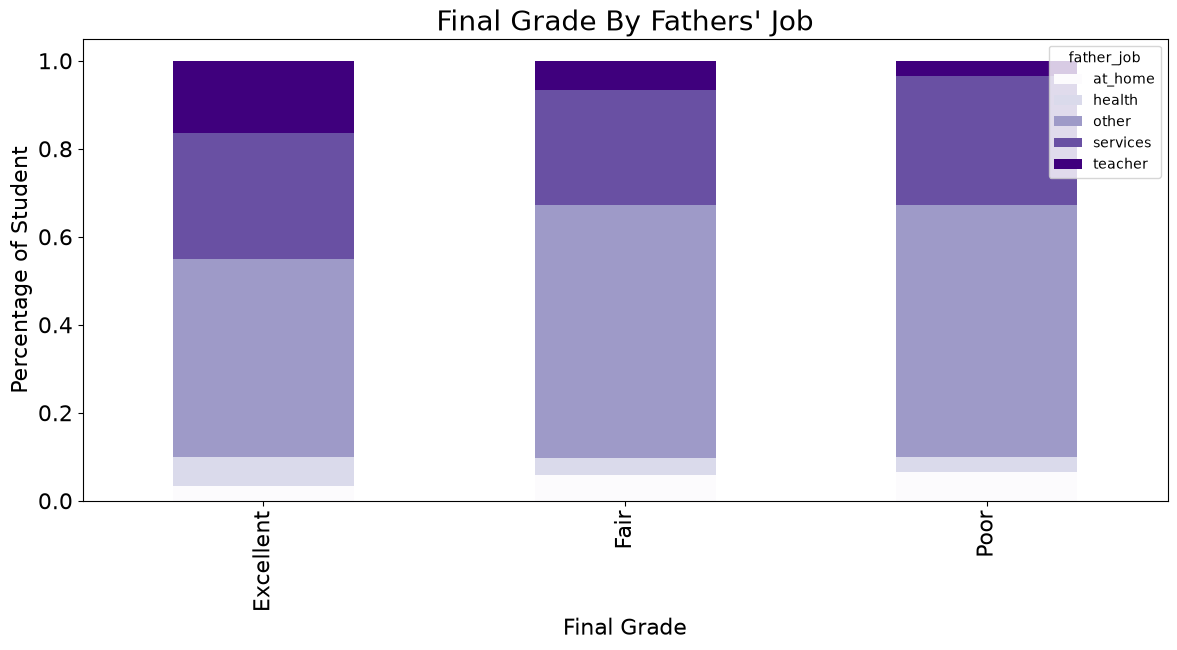

In [86]:
out_tab = pd.crosstab(df.father_job, df.remarks)
out_perc = out_tab.apply(perc)
out_perc = out_perc.T
out_perc.plot.bar(colormap="Purples", fontsize=16, figsize=(14,6), stacked = True)
plt.title("Final Grade By Fathers' Job", fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

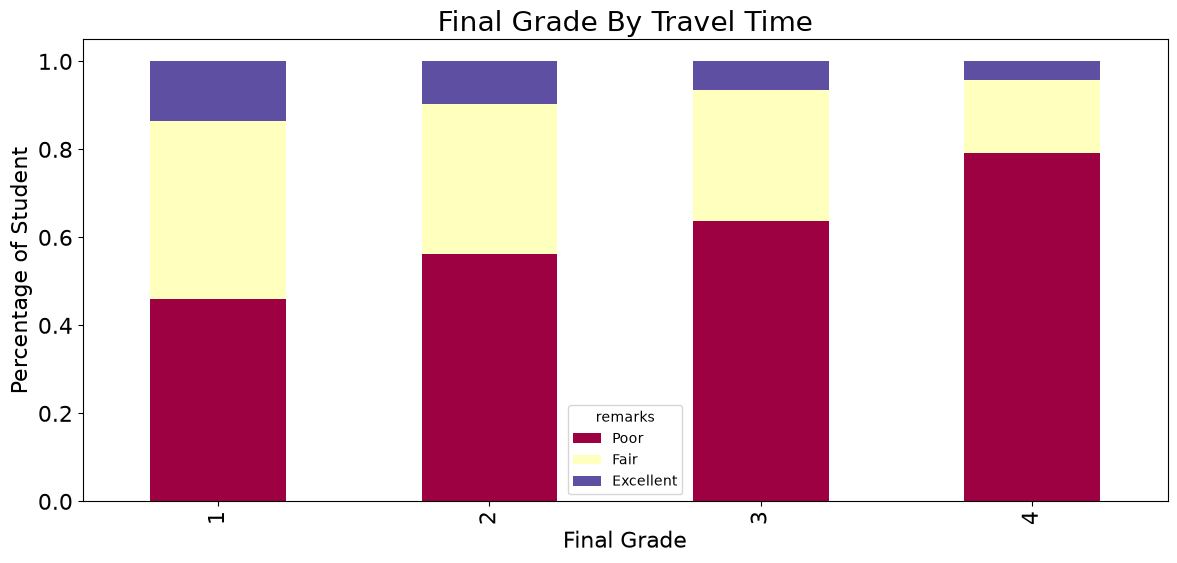

In [87]:
out_tab = pd.crosstab(df.remarks, df.travel_time)
out_perc = out_tab.apply(perc).reindex(index)
out_perc = out_perc.T
out_perc.plot.bar(colormap="Spectral", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade By Travel Time', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)
plt.show()

<Axes: xlabel='travel_time', ylabel='final_grade'>

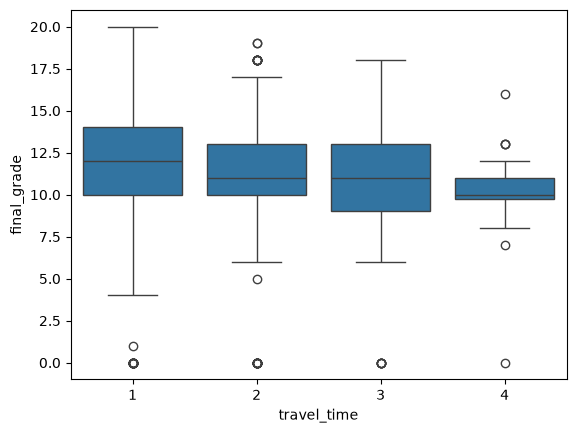

In [88]:
sns.boxplot(data = df, x = "travel_time", y = "final_grade")

Text(0, 0.5, 'Percentage of Student')

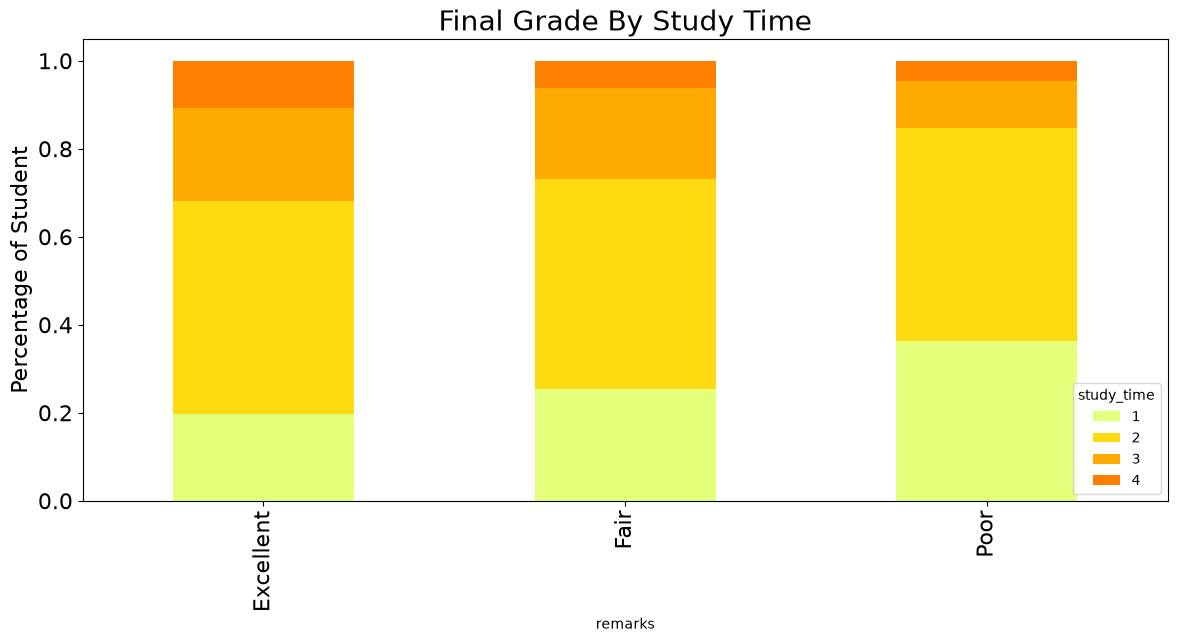

In [89]:
out_tab = pd.crosstab(df.study_time, df.remarks)
out_perc = out_tab.apply(perc)
out_perc = out_perc.T
out_perc.plot.bar(colormap="Wistia", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade By Study Time', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)

Text(0.5, 0, 'Final Grade')

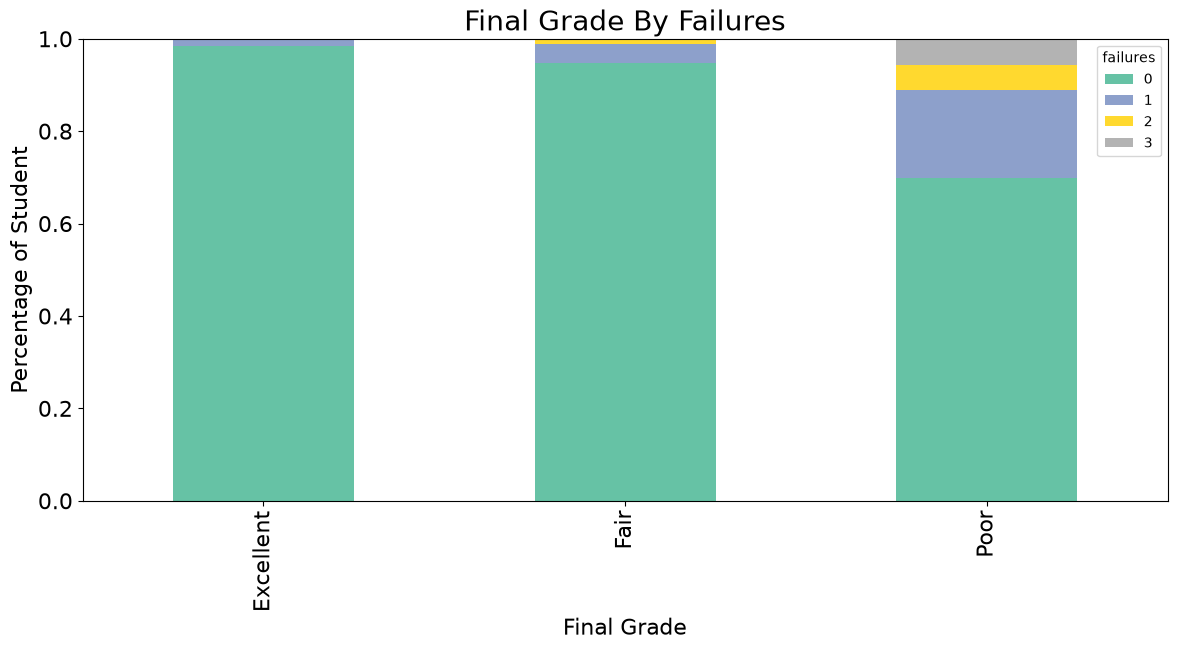

In [90]:
out_tab = pd.crosstab(df.failures, df.remarks)
out_perc = out_tab.apply(perc)
out_perc = out_perc.T
out_perc.plot.bar(colormap="Set2", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade By Failures', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

Text(0.5, 0, 'Final Grade')

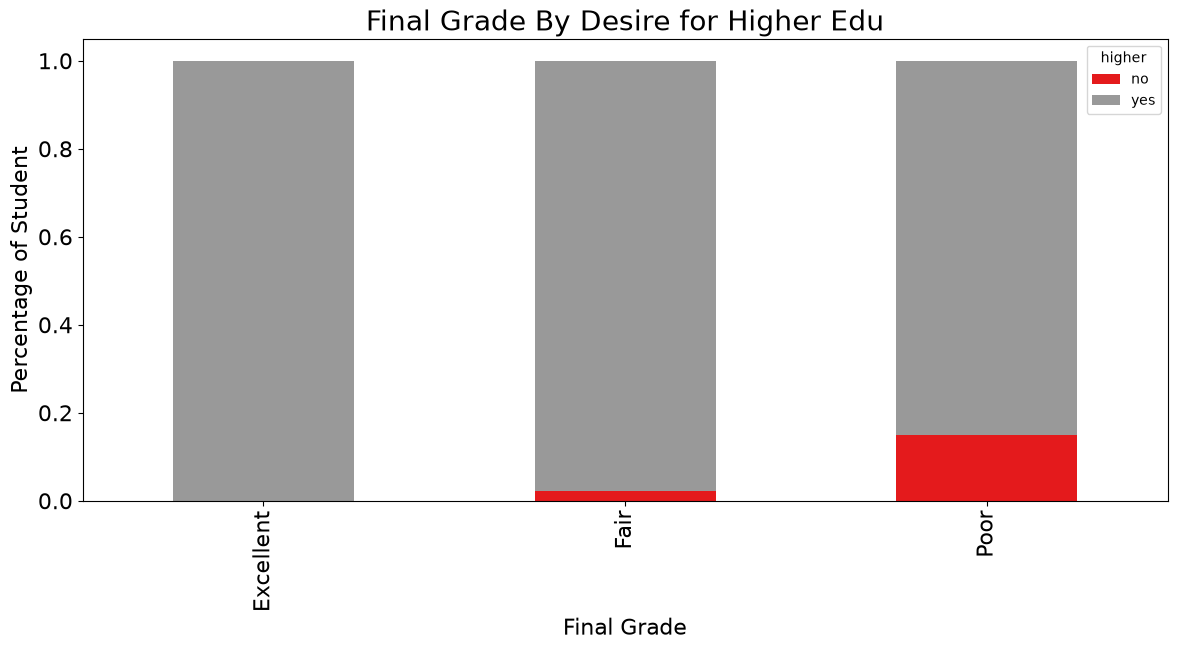

In [91]:
out_tab = pd.crosstab(df.higher, df.remarks)
out_perc = out_tab.apply(perc)
out_perc = out_perc.T
out_perc.plot.bar(colormap="Set1", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade By Desire for Higher Edu', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)


Text(0.5, 0, 'Final Grade')

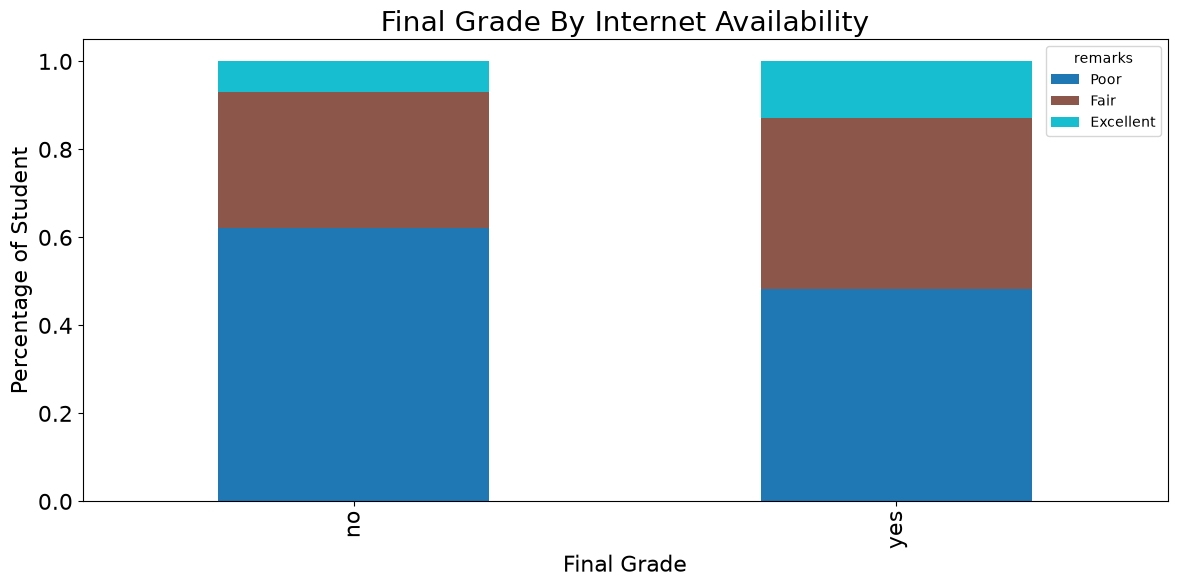

In [92]:
out_tab = pd.crosstab(df.remarks, df.internet)
out_perc = out_tab.apply(perc).reindex(index)
out_perc = out_perc.T
out_perc.plot.bar(colormap="tab10", fontsize=16, figsize=(14,6), stacked = True)
plt.title('Final Grade By Internet Availability', fontsize=20)
plt.ylabel('Percentage of Student', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)

In [101]:
dfd = df.copy()

In [102]:
dfd.columns

Index(['school', 'sex', 'age', 'address', 'fam_size', 'parents_status',
       'mother_edu', 'father_edu', 'mother_job', 'father_job', 'reason',
       'guardian', 'travel_time', 'study_time', 'failures', 'school_support',
       'fam_support', 'paid_courses', 'activities', 'nursery', 'higher',
       'internet', 'romantic', 'fam_rel', 'free_time', 'go_out', 'weekday_alc',
       'weekend_alc', 'health', 'absences', 'G1', 'G2', 'final_grade',
       'remarks'],
      dtype='str')

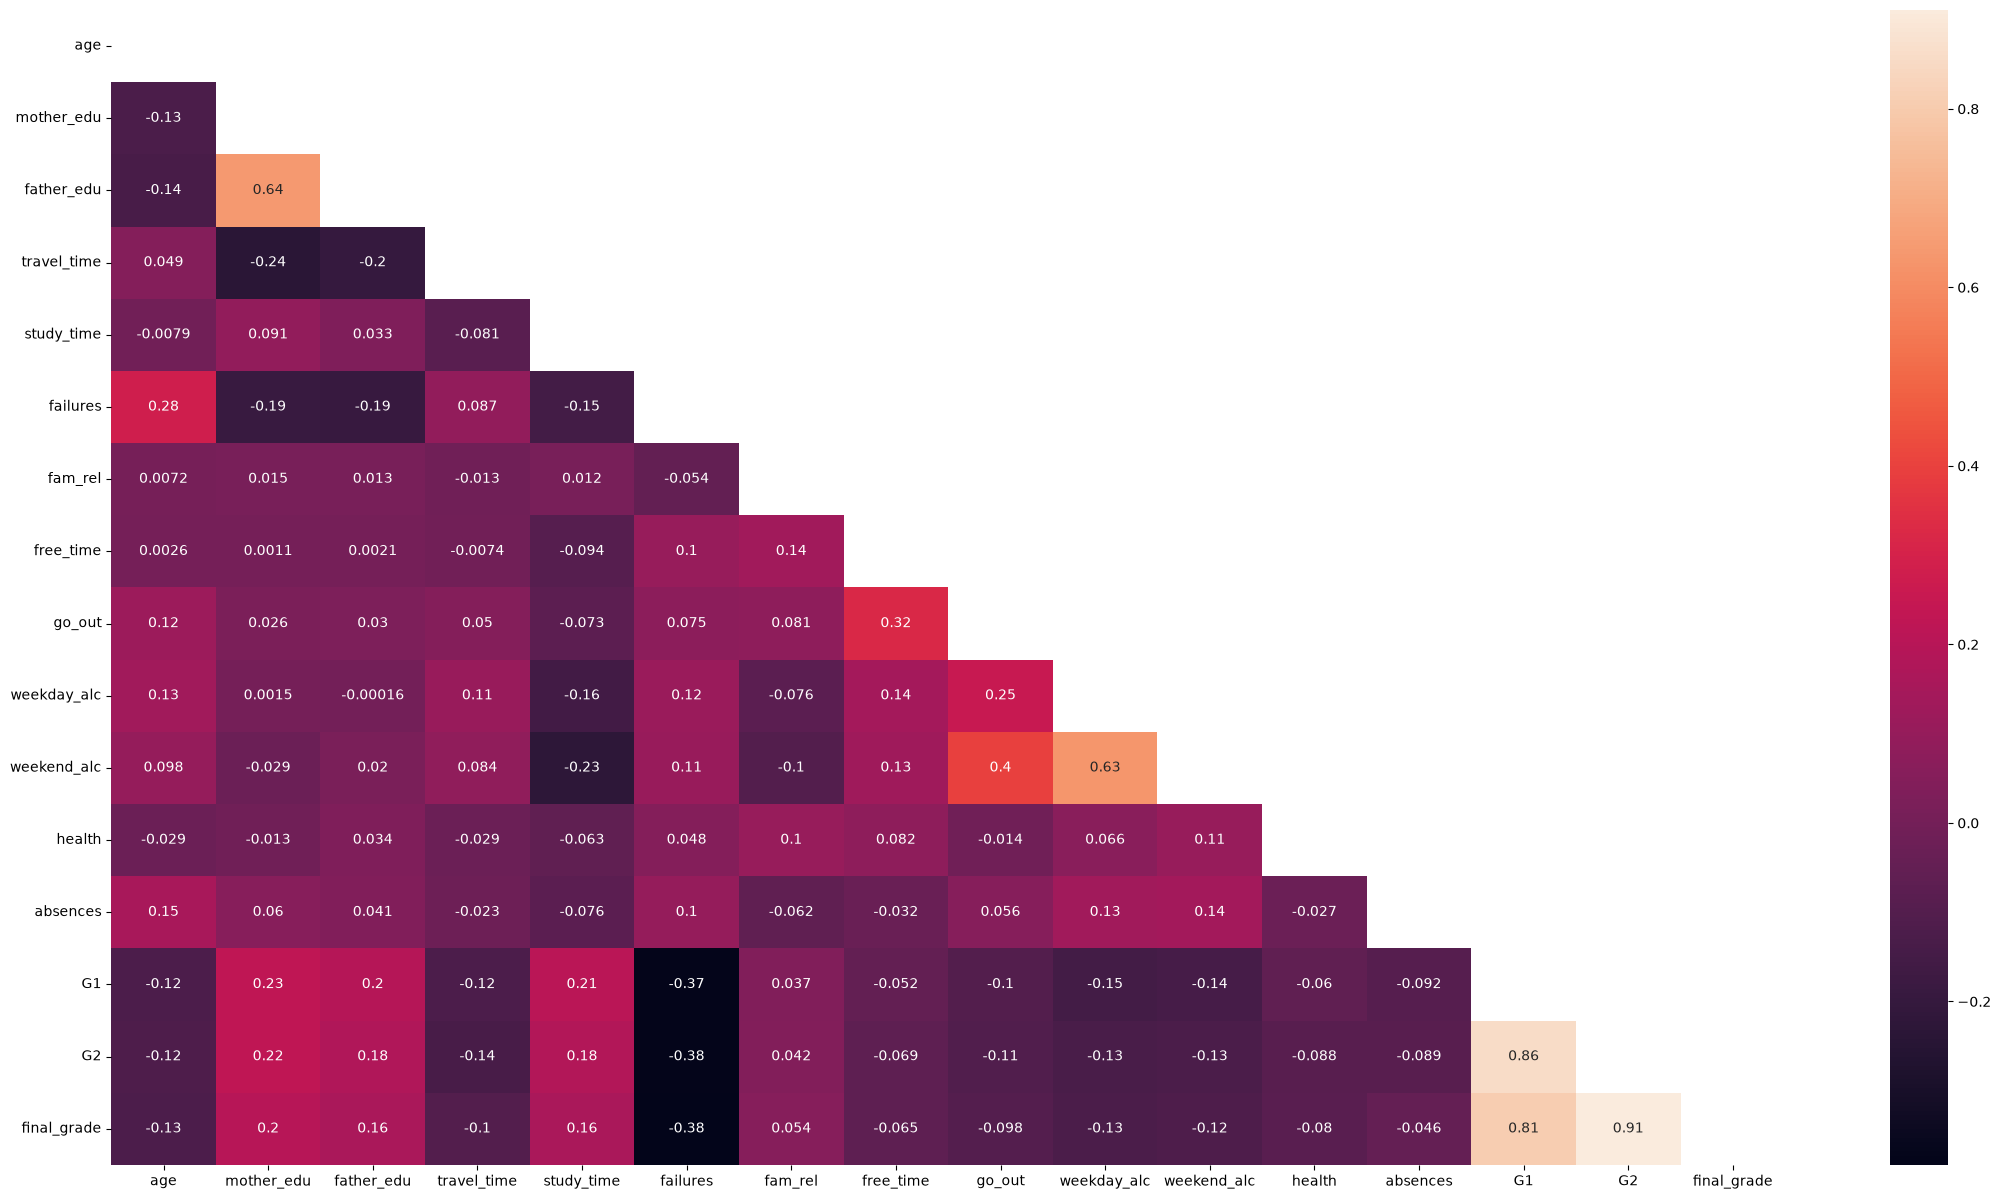

In [104]:

corr = dfd.corr(numeric_only=True)
mat = np.triu(corr)
fig, ax = plt.subplots(figsize=(27, 15))
sns.heatmap(corr, annot=True, mask=mat)
plt.show()